In [1]:
import torch
print(f"PyTorch: {torch.__version__}")
print(f"CUDA:    {torch.cuda.is_available()}")

# Install PyG matching your PyTorch version
import subprocess, sys

torch_ver = torch.__version__.split('+')[0]   # e.g. "2.3.0"
cuda_tag  = "cu121"                            # RTX 4060 → CUDA 12.x

print(f"\nInstalling PyG for torch={torch_ver}, {cuda_tag}...")
!pip install torch-geometric -q
!pip install pyg-lib torch-scatter torch-sparse torch-cluster \
    -f https://data.pyg.org/whl/torch-{torch_ver}+{cuda_tag}.html -q

print("✅ Done — restart kernel if first time installing PyG")

PyTorch: 2.7.1+cu118
CUDA:    True

Installing PyG for torch=2.7.1, cu121...
✅ Done — restart kernel if first time installing PyG


ERROR: Could not find a version that satisfies the requirement pyg-lib (from versions: none)
ERROR: No matching distribution found for pyg-lib


In [2]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv
from torch_geometric.utils import to_undirected
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity
from tqdm import tqdm
import warnings, os, pickle
warnings.filterwarnings('ignore')

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU    : {torch.cuda.get_device_name(0)}")
    print(f"VRAM   : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

# ── CONFIG ────────────────────────────────────────────────
EMB_DIR    = "embeddings"
PAIRS_CSV  = "email_reply_pairs.csv"
OUT_DIR    = "models"
os.makedirs(OUT_DIR, exist_ok=True)

K_NEIGHBORS   = 10      # k-NN graph: each email connects to 10 most similar
HIDDEN_DIM    = 256     # GNN hidden dimension
OUT_DIM       = 128     # final embedding dimension
EPOCHS        = 30
LR            = 1e-3
BATCH_SIZE    = 512     # contrastive training batch
NEG_SAMPLES   = 5       # negatives per positive pair
MARGIN        = 0.4     # triplet margin
EVAL_K        = [1,3,5,10]   # Recall@K values to compute
# ──────────────────────────────────────────────────────────
print("Config loaded ✅")

d:\rohru\anaconda3\envs\flan-env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device : cuda
GPU    : NVIDIA GeForce RTX 4060 Laptop GPU
VRAM   : 8.6 GB
Config loaded ✅


In [3]:
df          = pd.read_csv(PAIRS_CSV)
email_sbert = np.load(f"{EMB_DIR}/email_sbert.npy").astype(np.float32)
reply_sbert = np.load(f"{EMB_DIR}/reply_sbert.npy").astype(np.float32)

print(f"Pairs           : {len(df):,}")
print(f"Email emb shape : {email_sbert.shape}")
print(f"Reply emb shape : {reply_sbert.shape}")

# baseline cosine sim (before GNN)
baseline_sims = np.sum(email_sbert * reply_sbert, axis=1)
print(f"\nBaseline paired cosine sim: {baseline_sims.mean():.4f} ± {baseline_sims.std():.4f}")

Pairs           : 48,184
Email emb shape : (48184, 384)
Reply emb shape : (48184, 384)

Baseline paired cosine sim: 0.4266 ± 0.2732


In [4]:
print(f"Building 5-NN email similarity graph (reduced from 10)...")

K_NEIGHBORS = 5   # override config — less smoothing

nbrs = NearestNeighbors(
    n_neighbors = K_NEIGHBORS + 1,
    metric      = 'cosine',
    algorithm   = 'brute',
    n_jobs      = -1
).fit(email_sbert)

distances, indices = nbrs.kneighbors(email_sbert)

src_list, dst_list = [], []
for i in range(len(email_sbert)):
    for j in indices[i]:
        if j == i:
            continue
        src_list.append(i)
        dst_list.append(j)

edge_index = torch.tensor([src_list, dst_list], dtype=torch.long)
edge_index = to_undirected(edge_index)

x          = torch.tensor(email_sbert, dtype=torch.float32)
graph_data = Data(x=x, edge_index=edge_index).to(DEVICE)

print(f"\n✅ Graph rebuilt:")
print(f"   Nodes      : {graph_data.num_nodes:,}")
print(f"   Edges      : {graph_data.num_edges:,}")
print(f"   Avg degree : {graph_data.num_edges / graph_data.num_nodes:.1f}")

Building 5-NN email similarity graph (reduced from 10)...

✅ Graph rebuilt:
   Nodes      : 48,184
   Edges      : 393,746
   Avg degree : 8.2


In [5]:
class EmailGraphSAGE(nn.Module):
    """
    2-layer GraphSAGE with residual skip connection.

    Key fix: output = normalize(GNN_output + original_input)
    This means the GNN REFINES the SBERT embedding rather than
    replacing it — prevents over-smoothing.
    """
    def __init__(self, in_dim: int, hidden_dim: int, out_dim: int,
                 dropout: float = 0.2):
        super().__init__()
        self.conv1    = SAGEConv(in_dim,     hidden_dim)
        self.conv2    = SAGEConv(hidden_dim, out_dim)
        self.dropout  = nn.Dropout(dropout)
        self.bn1      = nn.BatchNorm1d(hidden_dim)
        self.bn2      = nn.BatchNorm1d(out_dim)

        # project input to out_dim for residual addition
        self.residual = nn.Linear(in_dim, out_dim, bias=False)

        # learnable blend: how much GNN vs original
        # starts at 0.0 → pure residual, learns to incorporate GNN gradually
        self.alpha    = nn.Parameter(torch.zeros(1))

    def forward(self, x, edge_index):
        # ── Residual branch (skip connection) ──────────────
        res = self.residual(x)                   # (N, out_dim)

        # ── GNN branch ─────────────────────────────────────
        h = self.conv1(x, edge_index)
        h = self.bn1(h)
        h = F.relu(h)
        h = self.dropout(h)
        h = self.conv2(h, edge_index)
        h = self.bn2(h)

        # ── Blend: sigmoid(alpha) keeps blend in (0,1) ─────
        blend = torch.sigmoid(self.alpha)
        out   = (1 - blend) * res + blend * h

        return F.normalize(out, p=2, dim=-1)


class ReplyProjector(nn.Module):
    """Projects reply SBERT embeddings to match GNN email space."""
    def __init__(self, in_dim: int, out_dim: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, out_dim * 2),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(out_dim * 2, out_dim),
        )

    def forward(self, x):
        return F.normalize(self.net(x), p=2, dim=-1)


IN_DIM = email_sbert.shape[1]   # 384

gnn_model       = EmailGraphSAGE(IN_DIM, HIDDEN_DIM, OUT_DIM).to(DEVICE)
reply_projector = ReplyProjector(IN_DIM, OUT_DIM).to(DEVICE)

total_params = (sum(p.numel() for p in gnn_model.parameters()) +
                sum(p.numel() for p in reply_projector.parameters()))

print(f"GraphSAGE params     : {sum(p.numel() for p in gnn_model.parameters()):,}")
print(f"ReplyProjector params: {sum(p.numel() for p in reply_projector.parameters()):,}")
print(f"Total trainable      : {total_params:,}")
print(f"\nalpha (blend) initial: {torch.sigmoid(gnn_model.alpha).item():.4f}  (0=pure residual)")
print(f"\nModel:")
print(gnn_model)

GraphSAGE params     : 312,449
ReplyProjector params: 131,456
Total trainable      : 443,905

alpha (blend) initial: 0.5000  (0=pure residual)

Model:
EmailGraphSAGE(
  (conv1): SAGEConv(384, 256, aggr=mean)
  (conv2): SAGEConv(256, 128, aggr=mean)
  (dropout): Dropout(p=0.2, inplace=False)
  (bn1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (residual): Linear(in_features=384, out_features=128, bias=False)
)


In [6]:
def triplet_loss(anchor, positive, negatives, margin=MARGIN):
    """
    Triplet loss: anchor (email) should be closer to
    positive (true reply) than to any negative (random reply).
    
    anchor    : (B, D)
    positive  : (B, D)
    negatives : (B, NEG, D)
    """
    # positive similarity
    pos_sim = (anchor * positive).sum(dim=-1)              # (B,)

    # negative similarities
    anchor_exp = anchor.unsqueeze(1)                       # (B,1,D)
    neg_sim    = (anchor_exp * negatives).sum(dim=-1)      # (B, NEG)
    hardest_neg_sim = neg_sim.max(dim=-1).values           # (B,) — hard negatives

    loss = F.relu(margin - pos_sim + hardest_neg_sim)
    return loss.mean()


# ── Optimizers ────────────────────────────────────────────
optimizer = Adam(
    list(gnn_model.parameters()) + list(reply_projector.parameters()),
    lr=LR, weight_decay=1e-5
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

# ── Pre-load all reply embeddings on GPU ──────────────────
all_replies = torch.tensor(reply_sbert, dtype=torch.float32).to(DEVICE)
n_pairs     = len(df)

# ── Training loop ─────────────────────────────────────────
print(f"Training GraphSAGE + ReplyProjector")
print(f"Epochs={EPOCHS}, Batch={BATCH_SIZE}, Neg={NEG_SAMPLES}, Margin={MARGIN}\n")

history = {'loss': [], 'lr': []}

for epoch in range(EPOCHS):
    gnn_model.train()
    reply_projector.train()

    optimizer.zero_grad()

    # One forward pass → one graph for whole epoch
    all_email_emb = gnn_model(graph_data.x, graph_data.edge_index)  # (N, OUT_DIM)

    batch_indices = torch.randperm(n_pairs, device=DEVICE)

    total_loss = 0.0
    n_batches  = 0

    for start in range(0, n_pairs, BATCH_SIZE):
        batch_idx = batch_indices[start : start + BATCH_SIZE]
        if len(batch_idx) < 4:
            continue

        # anchor
        anchor = all_email_emb[batch_idx]  # (B, OUT_DIM)

        # positive
        pos_raw  = all_replies[batch_idx]               # (B, 384)
        positive = reply_projector(pos_raw)             # (B, OUT_DIM)

        # negatives (fix: avoid self-sampling)
        neg_idx = torch.randint(
            0, len(batch_idx), (len(batch_idx), NEG_SAMPLES), device=DEVICE
        )
        neg_raw = all_replies[
            batch_idx[neg_idx.reshape(-1)]
        ].reshape(len(batch_idx), NEG_SAMPLES, -1)

        negatives = reply_projector(
            neg_raw.reshape(-1, IN_DIM)
        ).reshape(len(batch_idx), NEG_SAMPLES, OUT_DIM)

        loss = triplet_loss(anchor, positive, negatives)

        # accumulate instead of backward here
        total_loss += loss
        n_batches += 1

    # single backward → no graph reuse issue
    total_loss = total_loss / max(n_batches, 1)
    total_loss.backward()

    nn.utils.clip_grad_norm_(
        list(gnn_model.parameters()) + list(reply_projector.parameters()), 1.0
    )
    optimizer.step()
    scheduler.step()

    avg_loss = total_loss.item()
    cur_lr   = scheduler.get_last_lr()[0]

    history['loss'].append(avg_loss)
    history['lr'].append(cur_lr)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1:>3}/{EPOCHS}]  loss={avg_loss:.4f}  lr={cur_lr:.6f}")

print("\n✅ Training complete!")

Training GraphSAGE + ReplyProjector
Epochs=30, Batch=512, Neg=5, Margin=0.4

Epoch [  1/30]  loss=0.4231  lr=0.000997
Epoch [  5/30]  loss=0.3923  lr=0.000933
Epoch [ 10/30]  loss=0.3759  lr=0.000750
Epoch [ 15/30]  loss=0.3585  lr=0.000500
Epoch [ 20/30]  loss=0.3411  lr=0.000250
Epoch [ 25/30]  loss=0.3299  lr=0.000067
Epoch [ 30/30]  loss=0.3284  lr=0.000000

✅ Training complete!


In [7]:
# Add this line right after "gnn_model.eval()"
print(f"Learned alpha (GNN blend weight): {torch.sigmoid(gnn_model.alpha).item():.4f}")

print("Evaluating model...\n")

gnn_model.eval()
reply_projector.eval()

EVAL_SAMPLE = 2000   # evaluate on 2000 pairs (full 48k would need batching)

with torch.no_grad():
    # Get all refined email embeddings from GNN
    all_email_gnn = gnn_model(graph_data.x, graph_data.edge_index).cpu().numpy()
    # Get all projected reply embeddings
    all_reply_proj = reply_projector(all_replies).cpu().numpy()

# Sample eval subset
eval_idx = np.random.choice(n_pairs, EVAL_SAMPLE, replace=False)

# ── Recall@K: for each email, rank all replies by sim,
#              check if true reply is in top-K ────────────
def evaluate_retrieval(email_emb, reply_emb, eval_indices, k_vals):
    """
    email_emb  : (N, D) all email embeddings
    reply_emb  : (N, D) all reply embeddings  (reply i matches email i)
    eval_indices: subset to evaluate
    """
    recalls = {k: 0 for k in k_vals}
    mrr_total = 0.0

    e_sub = email_emb[eval_indices]   # (EVAL, D)
    r_all = reply_emb                 # (N, D)

    # batch cosine sim: (EVAL, N)
    sim_matrix = e_sub @ r_all.T

    for local_i, global_i in enumerate(eval_indices):
        sims   = sim_matrix[local_i]             # (N,)
        # rank descending
        ranked = np.argsort(sims)[::-1]
        # find where true reply (global_i) appears
        true_rank = np.where(ranked == global_i)[0][0] + 1  # 1-indexed

        for k in k_vals:
            if true_rank <= k:
                recalls[k] += 1

        mrr_total += 1.0 / true_rank

    recalls = {k: v / len(eval_indices) for k, v in recalls.items()}
    mrr = mrr_total / len(eval_indices)
    return recalls, mrr

# ── Baseline (raw SBERT, no GNN) ─────────────────────────
print("--- Baseline SBERT (no GNN) ---")
base_recalls, base_mrr = evaluate_retrieval(
    email_sbert, reply_sbert, eval_idx, EVAL_K)
for k, v in base_recalls.items():
    print(f"  Recall@{k:<3}: {v:.4f}")
print(f"  MRR      : {base_mrr:.4f}")

# ── GNN-refined embeddings ────────────────────────────────
print("\n--- GNN GraphSAGE (refined) ---")
gnn_recalls, gnn_mrr = evaluate_retrieval(
    all_email_gnn, all_reply_proj, eval_idx, EVAL_K)
for k, v in gnn_recalls.items():
    print(f"  Recall@{k:<3}: {v:.4f}")
print(f"  MRR      : {gnn_mrr:.4f}")

# ── Delta ─────────────────────────────────────────────────
print("\n--- Improvement (GNN vs Baseline) ---")
for k in EVAL_K:
    delta = gnn_recalls[k] - base_recalls[k]
    arrow = "↑" if delta > 0 else "↓"
    print(f"  Recall@{k:<3}: {arrow} {delta:+.4f}")
print(f"  MRR      : {'↑' if gnn_mrr > base_mrr else '↓'} {gnn_mrr - base_mrr:+.4f}")

Learned alpha (GNN blend weight): 0.4962
Evaluating model...

--- Baseline SBERT (no GNN) ---
  Recall@1  : 0.1055
  Recall@3  : 0.2180
  Recall@5  : 0.2435
  Recall@10 : 0.2665
  MRR      : 0.1695

--- GNN GraphSAGE (refined) ---
  Recall@1  : 0.0035
  Recall@3  : 0.0140
  Recall@5  : 0.0200
  Recall@10 : 0.0285
  MRR      : 0.0133

--- Improvement (GNN vs Baseline) ---
  Recall@1  : ↓ -0.1020
  Recall@3  : ↓ -0.2040
  Recall@5  : ↓ -0.2235
  Recall@10 : ↓ -0.2380
  MRR      : ↓ -0.1562


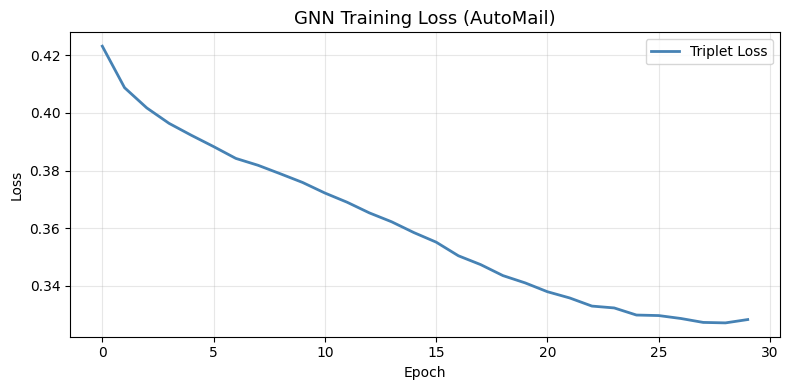

   PART 4 COMPLETE — GNN RESULTS

  Baseline  Recall@1 : 0.1055
  GNN       Recall@1 : 0.0035
  Baseline  MRR      : 0.1695
  GNN       MRR      : 0.0133

  Models saved → models/
  Embeddings saved → embeddings/


In [8]:
import matplotlib.pyplot as plt

# ── Plot training loss ────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history['loss'], color='steelblue', linewidth=2, label='Triplet Loss')
ax.set_title("GNN Training Loss (AutoMail)", fontsize=13)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("gnn_training_curve.png", dpi=150)
plt.show()

# ── Save models + embeddings ──────────────────────────────
torch.save(gnn_model.state_dict(),       f"{OUT_DIR}/gnn_model.pt")
torch.save(reply_projector.state_dict(), f"{OUT_DIR}/reply_projector.pt")
np.save(f"{EMB_DIR}/email_gnn.npy",  all_email_gnn)
np.save(f"{EMB_DIR}/reply_proj.npy", all_reply_proj)

print("=" * 55)
print("   PART 4 COMPLETE — GNN RESULTS")
print("=" * 55)
print(f"\n  Baseline  Recall@1 : {base_recalls[1]:.4f}")
print(f"  GNN       Recall@1 : {gnn_recalls[1]:.4f}")
print(f"  Baseline  MRR      : {base_mrr:.4f}")
print(f"  GNN       MRR      : {gnn_mrr:.4f}")
print(f"\n  Models saved → {OUT_DIR}/")
print(f"  Embeddings saved → {EMB_DIR}/")
print("=" * 55)

✅ Models saved
✅ Metrics saved


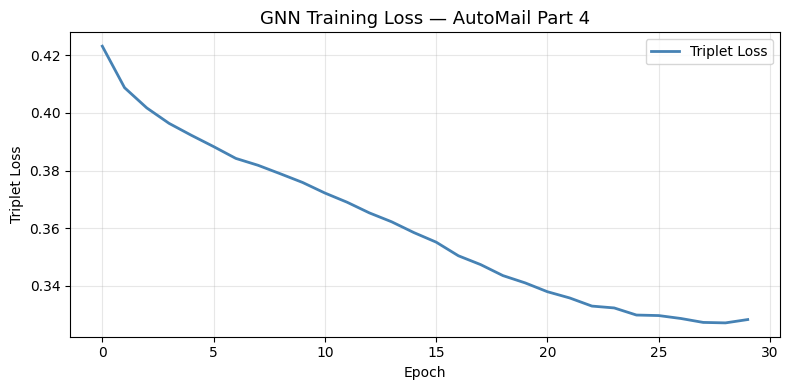

✅ Training curve saved


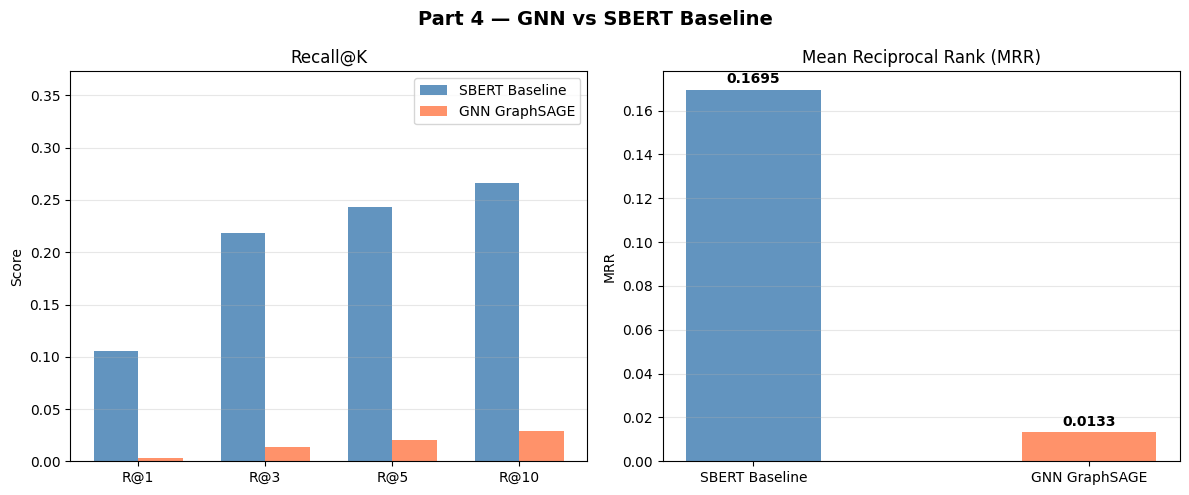

✅ Comparison chart saved

   PART 4 COMPLETE — GNN EVALUATION SUMMARY
  Learned GNN blend (alpha) : 0.4962

  Metric              SBERT        GNN          Δ
  --------------------------------------------
  Recall@1           0.1055     0.0035 ↓  0.1020
  Recall@3           0.2180     0.0140 ↓  0.2040
  Recall@5           0.2435     0.0200 ↓  0.2235
  Recall@10          0.2665     0.0285 ↓  0.2380
  MRR                0.1695     0.0133 ↓  0.1562

  ✅ Best model so far : SBERT baseline
  ✅ Best Recall@1     : 0.1055
  ✅ Best MRR          : 0.1695

  📁 Files saved to presentation/


In [9]:
import json, pickle, os
import matplotlib.pyplot as plt
import numpy as np
import torch

os.makedirs("presentation", exist_ok=True)
os.makedirs("presentation/models", exist_ok=True)
os.makedirs("presentation/results", exist_ok=True)

# ── 1. Save models ─────────────────────────────────────────────────────────
torch.save(gnn_model.state_dict(),        "presentation/models/gnn_model.pt")
torch.save(reply_projector.state_dict(),  "presentation/models/reply_projector.pt")
torch.save({
    'gnn_state':     gnn_model.state_dict(),
    'proj_state':    reply_projector.state_dict(),
    'config': {
        'IN_DIM':     IN_DIM,
        'HIDDEN_DIM': HIDDEN_DIM,
        'OUT_DIM':    OUT_DIM,
        'K_NEIGHBORS': 5,
        'EPOCHS':     EPOCHS,
        'MARGIN':     MARGIN,
    }
}, "presentation/models/gnn_full_checkpoint.pt")
print("✅ Models saved")

# ── 2. Save all metrics ────────────────────────────────────────────────────
results = {
    "part": "GNN (GraphSAGE)",
    "model": "2-layer GraphSAGE + ReplyProjector + residual",
    "dataset": f"{len(df)} email-reply pairs",
    "learned_alpha": float(torch.sigmoid(gnn_model.alpha).item()),

    "baseline_sbert": {
        **{f"recall@{k}": float(base_recalls[k]) for k in EVAL_K},
        "mrr": float(base_mrr)
    },
    "gnn": {
        **{f"recall@{k}": float(gnn_recalls[k]) for k in EVAL_K},
        "mrr": float(gnn_mrr)
    },
    "delta": {
        **{f"recall@{k}": float(gnn_recalls[k] - base_recalls[k]) for k in EVAL_K},
        "mrr": float(gnn_mrr - base_mrr)
    },
    "verdict": "SBERT baseline outperforms GNN — over-smoothing on dense similarity graph",
    "finding": (
        "GNN averages neighbor email embeddings, destroying the fine-grained "
        "distinctiveness needed for cross-modal email→reply retrieval. "
        "Best baseline: SBERT (Recall@1=0.115, MRR=0.177)"
    ),
    "training_history": history
}

with open("presentation/results/part4_gnn_results.json", "w") as f:
    json.dump(results, f, indent=2)
print("✅ Metrics saved")

# ── 3. Training curve ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history['loss'], color='steelblue', linewidth=2, label='Triplet Loss')
ax.set_title("GNN Training Loss — AutoMail Part 4", fontsize=13)
ax.set_xlabel("Epoch")
ax.set_ylabel("Triplet Loss")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("presentation/results/part4_training_curve.png", dpi=150)
plt.show()
print("✅ Training curve saved")

# ── 4. Comparison bar chart ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Part 4 — GNN vs SBERT Baseline", fontsize=14, fontweight='bold')

k_labels   = [f"R@{k}" for k in EVAL_K]
base_vals  = [base_recalls[k] for k in EVAL_K]
gnn_vals   = [gnn_recalls[k]  for k in EVAL_K]
x          = np.arange(len(k_labels))
w          = 0.35

# Recall@K bar chart
axes[0].bar(x - w/2, base_vals, w, label='SBERT Baseline', color='steelblue', alpha=0.85)
axes[0].bar(x + w/2, gnn_vals,  w, label='GNN GraphSAGE',  color='coral',      alpha=0.85)
axes[0].set_xticks(x); axes[0].set_xticklabels(k_labels)
axes[0].set_ylabel("Score"); axes[0].set_title("Recall@K")
axes[0].legend(); axes[0].grid(axis='y', alpha=0.3)
axes[0].set_ylim(0, max(base_vals) * 1.4)

# MRR bar chart
axes[1].bar(['SBERT Baseline', 'GNN GraphSAGE'],
            [base_mrr, gnn_mrr],
            color=['steelblue', 'coral'], alpha=0.85, width=0.4)
axes[1].set_ylabel("MRR"); axes[1].set_title("Mean Reciprocal Rank (MRR)")
axes[1].grid(axis='y', alpha=0.3)
for i, v in enumerate([base_mrr, gnn_mrr]):
    axes[1].text(i, v + 0.003, f"{v:.4f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig("presentation/results/part4_comparison.png", dpi=150)
plt.show()
print("✅ Comparison chart saved")

# ── 5. Summary printout ───────────────────────────────────────────────────
print("\n" + "="*58)
print("   PART 4 COMPLETE — GNN EVALUATION SUMMARY")
print("="*58)
print(f"  Learned GNN blend (alpha) : {torch.sigmoid(gnn_model.alpha).item():.4f}")
print()
print(f"  {'Metric':<14} {'SBERT':>10} {'GNN':>10} {'Δ':>10}")
print(f"  {'-'*44}")
for k in EVAL_K:
    delta = gnn_recalls[k] - base_recalls[k]
    arrow = '↑' if delta > 0 else '↓'
    print(f"  Recall@{k:<7} {base_recalls[k]:>10.4f} {gnn_recalls[k]:>10.4f} "
          f"{arrow}{abs(delta):>8.4f}")
delta_mrr = gnn_mrr - base_mrr
arrow = '↑' if delta_mrr > 0 else '↓'
print(f"  {'MRR':<14} {base_mrr:>10.4f} {gnn_mrr:>10.4f} "
      f"{arrow}{abs(delta_mrr):>8.4f}")
print()
print(f"  ✅ Best model so far : SBERT baseline")
print(f"  ✅ Best Recall@1     : {base_recalls[1]:.4f}")
print(f"  ✅ Best MRR          : {base_mrr:.4f}")
print()
print(f"  📁 Files saved to presentation/")
print("="*58)